In [4]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sb
%matplotlib inline

In [5]:
# Change parameters and the name of the output folder
param_1 = 'Match proportion'
param_2 = 'Match count'
output_folder = 'output-data-extracted/OUTPUT_MP_MC_extracted'

In [6]:
# Change parameters and the name of the output folder
param_1 = 'Trim quality'
param_2 = 'Trim window'
output_folder = 'output-data-extracted/OUTPUT_TQ_TW_extracted'

In [7]:
# Change parameters and the name of the output folder
param_1 = 'Match proportion'
param_2 = 'Trim quality'
output_folder = 'output-data-extracted/OUTPUT_MP_TQ_extracted'

In [8]:
parameters_df = pd.read_csv(f'{output_folder}/parameters.csv').drop_duplicates().set_index('Directory name')
parameters_df.head()

,Match proportion,Match count,Trim quality,Trim window
Directory name,,,,
Simulated_deletion_MP0.75_MC25_TQ12_TW4-OUTPUT,0.75,25,12,4
Simulated_deletion_MP0.75_MC25_TQ13_TW4-OUTPUT,0.75,25,13,4
Simulated_deletion_MP0.75_MC25_TQ14_TW4-OUTPUT,0.75,25,14,4
Simulated_deletion_MP0.75_MC25_TQ15_TW4-OUTPUT,0.75,25,15,4
Simulated_deletion_MP0.75_MC25_TQ16_TW4-OUTPUT,0.75,25,16,4


In [9]:
output_dirs = []
for dir in parameters_df.index:
    output_dirs.append(dir)
output_dirs

['Simulated_deletion_MP0.75_MC25_TQ12_TW4-OUTPUT',
 'Simulated_deletion_MP0.75_MC25_TQ13_TW4-OUTPUT',
 'Simulated_deletion_MP0.75_MC25_TQ14_TW4-OUTPUT',
 'Simulated_deletion_MP0.75_MC25_TQ15_TW4-OUTPUT',
 'Simulated_deletion_MP0.75_MC25_TQ16_TW4-OUTPUT',
 'Simulated_deletion_MP0.75_MC25_TQ17_TW4-OUTPUT',
 'Simulated_deletion_MP0.8_MC25_TQ12_TW4-OUTPUT',
 'Simulated_deletion_MP0.8_MC25_TQ13_TW4-OUTPUT',
 'Simulated_deletion_MP0.8_MC25_TQ14_TW4-OUTPUT',
 'Simulated_deletion_MP0.8_MC25_TQ15_TW4-OUTPUT',
 'Simulated_deletion_MP0.8_MC25_TQ16_TW4-OUTPUT',
 'Simulated_deletion_MP0.8_MC25_TQ17_TW4-OUTPUT',
 'Simulated_deletion_MP0.85_MC25_TQ12_TW4-OUTPUT',
 'Simulated_deletion_MP0.85_MC25_TQ13_TW4-OUTPUT',
 'Simulated_deletion_MP0.85_MC25_TQ14_TW4-OUTPUT',
 'Simulated_deletion_MP0.85_MC25_TQ15_TW4-OUTPUT',
 'Simulated_deletion_MP0.85_MC25_TQ16_TW4-OUTPUT',
 'Simulated_deletion_MP0.85_MC25_TQ17_TW4-OUTPUT',
 'Simulated_deletion_MP0.9_MC25_TQ12_TW4-OUTPUT',
 'Simulated_deletion_MP0.9_MC25_TQ13_T

In [10]:
merged_info_dfs = []
for dir in output_dirs:
    merged_info_dfs.append(pd.read_csv(f'{output_folder}/{dir}/merged.info', sep='\t'))
    merged_info_dfs[-1]['Directory name'] = dir
merged_info_dfs[0].head()

,sample,usedEntries,totalEntries,Directory name
0,fish4_s6_rep1,2406,7143,Simulated_deletion_MP0.75_MC25_TQ12_TW4-OUTPUT
1,fish5_s6_rep1,29523,39848,Simulated_deletion_MP0.75_MC25_TQ12_TW4-OUTPUT
2,fish6_s6_rep1,17940,25842,Simulated_deletion_MP0.75_MC25_TQ12_TW4-OUTPUT
3,fish8_s6_rep1,67464,75786,Simulated_deletion_MP0.75_MC25_TQ12_TW4-OUTPUT
4,fish9_s6_rep1,28960,40527,Simulated_deletion_MP0.75_MC25_TQ12_TW4-OUTPUT


In [11]:
allreadcounts_dfs = {}
for dir in output_dirs:
    dirs = os.listdir(f'{output_folder}/{dir}')
    for i in range(len(dirs)):
        if not os.path.isdir(f'{output_folder}/{dir}/{dirs[i]}'):
            continue
        allreadcounts_dfs[dirs[i]] = pd.read_csv(f'{output_folder}/{dir}/{dirs[i]}/{dirs[i]}.allReadCounts', sep='\t')
        allreadcounts_dfs[dirs[i]]['Directory name'] = dir
        allreadcounts_dfs[dirs[i]]['Fish'] = dirs[i]
allreadcounts_dfs[next(iter(allreadcounts_dfs))].head()

,event,array,count,proportion,Directory name,Fish
0,57D+35_57D+35_57D+35_NONE_NONE_NONE_NONE_NONE_...,0,7588,0.250843,Simulated_deletion_MP0.99_MC25_TQ17_TW4-OUTPUT,fish38_s6_rep1
1,3D+37_39D+60_39D+60_9D+115_NONE_NONE_NONE_NONE...,1,6016,0.198876,Simulated_deletion_MP0.99_MC25_TQ17_TW4-OUTPUT,fish38_s6_rep1
2,84D+34_84D+34_84D+34_84D+34_NONE_NONE_1I+199+A...,2,4838,0.159934,Simulated_deletion_MP0.99_MC25_TQ17_TW4-OUTPUT,fish38_s6_rep1
3,3D+37_54D+65_54D+65_54D+65_NONE_NONE_NONE_NONE...,3,4307,0.142380,Simulated_deletion_MP0.99_MC25_TQ17_TW4-OUTPUT,fish38_s6_rep1
4,3D+37_27D+67_27D+67_9D+115_NONE_NONE_NONE_NONE...,4,2324,0.076826,Simulated_deletion_MP0.99_MC25_TQ17_TW4-OUTPUT,fish38_s6_rep1


In [12]:
results_df = pd.concat(merged_info_dfs)
print(results_df.info())
for col in parameters_df.columns:
    results_df[col] = results_df['Directory name'].map(parameters_df[col])
#results_df['usedEntriesProportion'] = results_df['usedEntries'].astype('float64') / results_df['totalEntries']
results_df['usedEntriesProportion'] = results_df['sample'].apply(lambda x: float(allreadcounts_dfs[x]['count'].sum())) / results_df['totalEntries']
results_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 0 to 6
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   sample          252 non-null    object
 1   usedEntries     252 non-null    int64 
 2   totalEntries    252 non-null    int64 
 3   Directory name  252 non-null    object
dtypes: int64(2), object(2)
memory usage: 9.8+ KB
None


,sample,usedEntries,totalEntries,Directory name,Match proportion,Match count,Trim quality,Trim window,usedEntriesProportion
0,fish4_s6_rep1,2406,7143,Simulated_deletion_MP0.75_MC25_TQ12_TW4-OUTPUT,0.75,25,12,4,0.267675
1,fish5_s6_rep1,29523,39848,Simulated_deletion_MP0.75_MC25_TQ12_TW4-OUTPUT,0.75,25,12,4,0.616367
2,fish6_s6_rep1,17940,25842,Simulated_deletion_MP0.75_MC25_TQ12_TW4-OUTPUT,0.75,25,12,4,0.545004
3,fish8_s6_rep1,67464,75786,Simulated_deletion_MP0.75_MC25_TQ12_TW4-OUTPUT,0.75,25,12,4,0.688386
4,fish9_s6_rep1,28960,40527,Simulated_deletion_MP0.75_MC25_TQ12_TW4-OUTPUT,0.75,25,12,4,0.592272


In [13]:
mean_results_df = results_df.groupby([param_1, param_2]).agg({
    'usedEntriesProportion': 'mean',
})
mean_results_df.tail(20)

usedEntriesProportion
Match proportion Trim quality                       
0.85             16                         0.582989
                 17                         0.589602
0.90             12                         0.582413
                 13                         0.582413
                 14                         0.582417
                 15                         0.582487
                 16                         0.582989
                 17                         0.589602
0.95             12                         0.582413
                 13                         0.582413
                 14                         0.582417
                 15                         0.582487
                 16                         0.582989
                 17                         0.589602
0.99             12                         0.582413
                 13                         0.582413
                 14                         0.582417
                 15                         0.582487
                 16                         0.582989
                 17                         0.589602

The heatmap shows the mean proportion of used entries for each parameter combo.

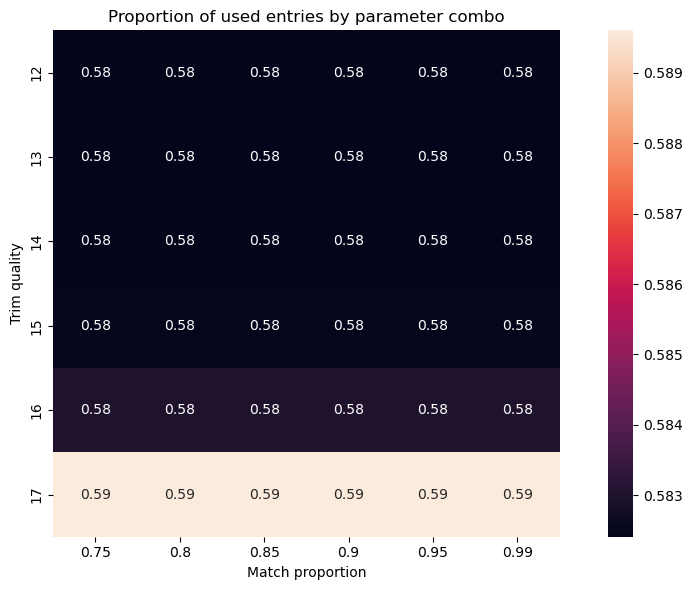

In [14]:
fig, ax = plt.subplots(figsize=(10,6))
pivot_data = mean_results_df.reset_index().pivot(index=param_2, columns=param_1, values='usedEntriesProportion')
sb.heatmap(pivot_data, annot=True, ax=ax, square=True)
plt.title('Proportion of used entries by parameter combo')
plt.tight_layout()
plt.show()

Lineplots show how the proportion of used entries for each sample changes depending on the paramaters chosen.

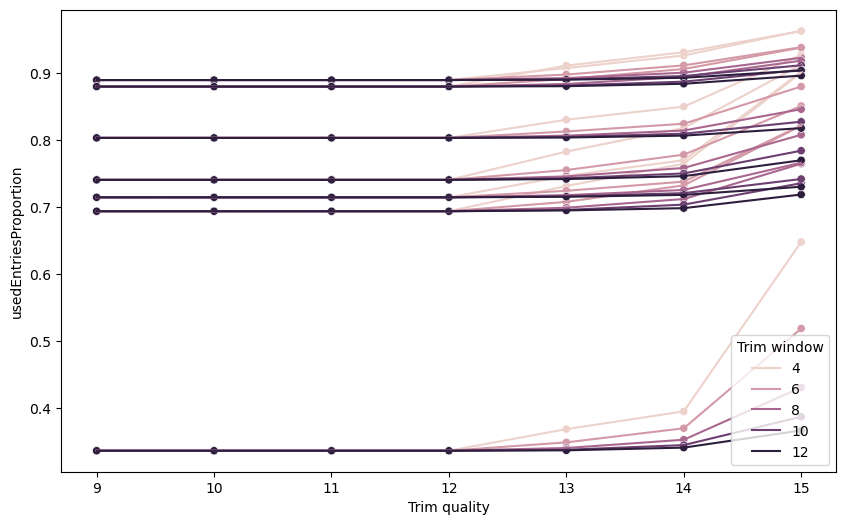

In [16]:
fig, ax = plt.subplots(figsize=(10,6))
sb.scatterplot(data=results_df, x=param_1, y='usedEntriesProportion', ax=ax, hue=param_2, legend=False)
sb.lineplot(data=results_df, x=param_1, y='usedEntriesProportion', hue=param_2, estimator=None, units='sample', ax=ax)
plt.show()

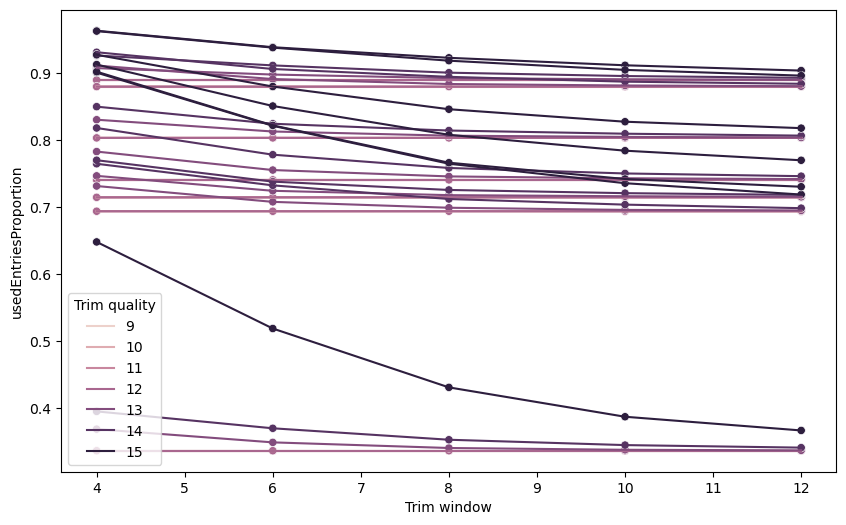

In [17]:
fig, ax = plt.subplots(figsize=(10,6))
sb.scatterplot(data=results_df, x=param_2, y='usedEntriesProportion', ax=ax, hue=param_1, legend=False)
sb.lineplot(data=results_df, x=param_2, y='usedEntriesProportion', hue=param_1, estimator=None, units='sample', ax=ax)
plt.show()